# Face Preprocessing — VidTIMIT

**Project:** Hierarchical Multimodal Biometric Verification System  
**Stage:** Face preprocessing  
**Dataset:** VidTIMIT

## Purpose of this notebook
This notebook presents and explains the face-preprocessing work already completed in the project. It focuses on visual examples, the actual detection and padding logic, and the measured results.

**Important:** The main pipeline remains in `src/preprocessing/face_preprocessing.py`. This notebook does not rerun preprocessing on all 103,542 frames. It loads the existing report and processed images, and runs the detector only on one selected example so we can visualize the stages clearly.


## 1. Imports and project paths

Run this notebook from the project folder or its `notebooks` subfolder. The cell locates the project root automatically.


In [1]:
from pathlib import Path
import random
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in candidates if (p / 'src' / 'preprocessing' / 'face_preprocessing.py').exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Project root not found. Open this notebook from the project, '
        'or set PROJECT_ROOT manually.'
    )

RAW_PATH = PROJECT_ROOT / 'data' / 'raw' / 'vidtimit'
PROCESSED_PATH = PROJECT_ROOT / 'data' / 'processed' / 'face'
REPORT_PATH = PROJECT_ROOT / 'data' / 'metadata' / 'face_preprocessing_report.csv'

print('Project root:', PROJECT_ROOT)
print('Raw dataset exists:', RAW_PATH.exists())
print('Processed faces exist:', PROCESSED_PATH.exists())
print('Preprocessing report exists:', REPORT_PATH.exists())


Project root: c:\samawork\uni\supervised\task2\Biometric-Verification-System
Raw dataset exists: True
Processed faces exist: True
Preprocessing report exists: True


## 2. Dataset overview

The dataset validation completed earlier reported **43 speakers**, **430 audio WAV files**, and **103,542 video frames**. The next cell checks the speaker folders and displays a few speaker IDs.


In [2]:
speaker_dirs = sorted(p for p in RAW_PATH.iterdir() if p.is_dir())
print('Number of speaker folders:', len(speaker_dirs))
print('Example speaker IDs:', [p.name for p in speaker_dirs[:10]])


Number of speaker folders: 43
Example speaker IDs: ['fadg0', 'faks0', 'fcft0', 'fcmh0', 'fcmr0', 'fcrh0', 'fdac1', 'fdms0', 'fdrd1', 'fedw0']


## 3. Preprocessing workflow

The implementation uses the following steps:

1. Read the original frame using OpenCV.
2. Convert the frame to **grayscale**.
3. Detect a face using three attempts: **Haar frontal**, **Haar profile**, and **Haar profile after horizontal flipping**.
4. Select the largest detected bounding box.
5. Expand the detected box by **15% padding** in both width and height, while keeping the crop inside the image boundaries.
6. Crop the padded face region.
7. Resize the crop to **128 × 128** using `INTER_AREA`.

All of these are traditional Computer Vision operations; the face detector is Haar Cascade, not a Deep Learning model.


## 4. Load the same Haar Cascade detectors

This cell initializes the same two cascade files used by the project's Python implementation.


In [3]:
CASCADE_DIR = Path(cv2.data.haarcascades)
FRONTAL_DETECTOR = cv2.CascadeClassifier(str(CASCADE_DIR / 'haarcascade_frontalface_default.xml'))
PROFILE_DETECTOR = cv2.CascadeClassifier(str(CASCADE_DIR / 'haarcascade_profileface.xml'))

if FRONTAL_DETECTOR.empty() or PROFILE_DETECTOR.empty():
    raise RuntimeError('Could not load Haar Cascade classifiers!')

print('Frontal detector loaded:', not FRONTAL_DETECTOR.empty())
print('Profile detector loaded:', not PROFILE_DETECTOR.empty())


Frontal detector loaded: True
Profile detector loaded: True


## 5. Face detection function

The function below follows the detection logic in `face_preprocessing.py`. It collects detections from all three passes, converts the flipped-image coordinates back to the original frame, and returns the largest detected face.


In [4]:
def detect_face(gray):
    detections = []

    # 1) Frontal face
    frontal_faces = FRONTAL_DETECTOR.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=4, minSize=(30, 30)
    )
    detections.extend(list(frontal_faces))

    # 2) Profile face
    profile_faces = PROFILE_DETECTOR.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=4, minSize=(30, 30)
    )
    detections.extend(list(profile_faces))

    # 3) Profile face after horizontal flip
    flipped = cv2.flip(gray, 1)
    flipped_faces = PROFILE_DETECTOR.detectMultiScale(
        flipped, scaleFactor=1.1, minNeighbors=4, minSize=(30, 30)
    )
    image_width = gray.shape[1]
    for x, y, w, h in flipped_faces:
        original_x = image_width - (x + w)
        detections.append((original_x, y, w, h))

    if not detections:
        return None

    return max(detections, key=lambda box: box[2] * box[3])


## 6. Visual example: detection, padding, and resizing

This is the main visual demonstration for the discussion. We select one successful frame from a speech sequence (not a head-rotation sequence), then show:

- the original frame with the detected face bounding box;
- the grayscale face crop **before padding**;
- the crop **after adding 15% padding**;
- the final **128 × 128** image.

The notebook processes only this sample for visualization; it does not rerun the complete dataset pipeline.


In [5]:
if not REPORT_PATH.exists():
    raise FileNotFoundError(f'Preprocessing report not found: {REPORT_PATH}')
report = pd.read_csv(REPORT_PATH)
display(report.head())
print('Report rows:', len(report))
print('Report columns:', report.columns.tolist())


,speaker,sequence,original_file,processed_file,status
0,fadg0,head,C:\samawork\uni\supervised\task2\Biometric-Ver...,C:\samawork\uni\supervised\task2\Biometric-Ver...,Success
1,fadg0,head,C:\samawork\uni\supervised\task2\Biometric-Ver...,C:\samawork\uni\supervised\task2\Biometric-Ver...,Success
2,fadg0,head,C:\samawork\uni\supervised\task2\Biometric-Ver...,C:\samawork\uni\supervised\task2\Biometric-Ver...,Success
3,fadg0,head,C:\samawork\uni\supervised\task2\Biometric-Ver...,C:\samawork\uni\supervised\task2\Biometric-Ver...,Success
4,fadg0,head,C:\samawork\uni\supervised\task2\Biometric-Ver...,C:\samawork\uni\supervised\task2\Biometric-Ver...,Success


Report rows: 103542
Report columns: ['speaker', 'sequence', 'original_file', 'processed_file', 'status']


In [6]:
required_columns = {'speaker', 'sequence', 'original_file', 'processed_file', 'status'}
missing_columns = required_columns - set(report.columns)
if missing_columns:
    raise KeyError(f'Missing expected report columns: {missing_columns}')

# Prefer a successful speech-sequence example, excluding head-rotation sequences.
speech_rows = report[
    (report['status'] == 'Success') &
    (~report['sequence'].astype(str).str.lower().str.startswith('head')) &
    report['original_file'].notna() &
    report['processed_file'].notna()
]
if speech_rows.empty:
    raise RuntimeError('No successful speech-sequence examples were found in the report.')

sample = speech_rows.sample(1, random_state=7).iloc[0]
original_path = Path(sample['original_file'])
processed_path = Path(sample['processed_file'])
if not original_path.is_absolute():
    original_path = PROJECT_ROOT / original_path
if not processed_path.is_absolute():
    processed_path = PROJECT_ROOT / processed_path

print('Speaker:', sample['speaker'])
print('Sequence:', sample['sequence'])
print('Original frame:', original_path)
print('Saved processed face:', processed_path)


Speaker: fedw0
Sequence: sa1
Original frame: C:\samawork\uni\supervised\task2\Biometric-Verification-System\data\raw\vidtimit\fedw0\fedw0\video\sa1\017
Saved processed face: C:\samawork\uni\supervised\task2\Biometric-Verification-System\data\processed\face\fedw0\sa1\017.jpg


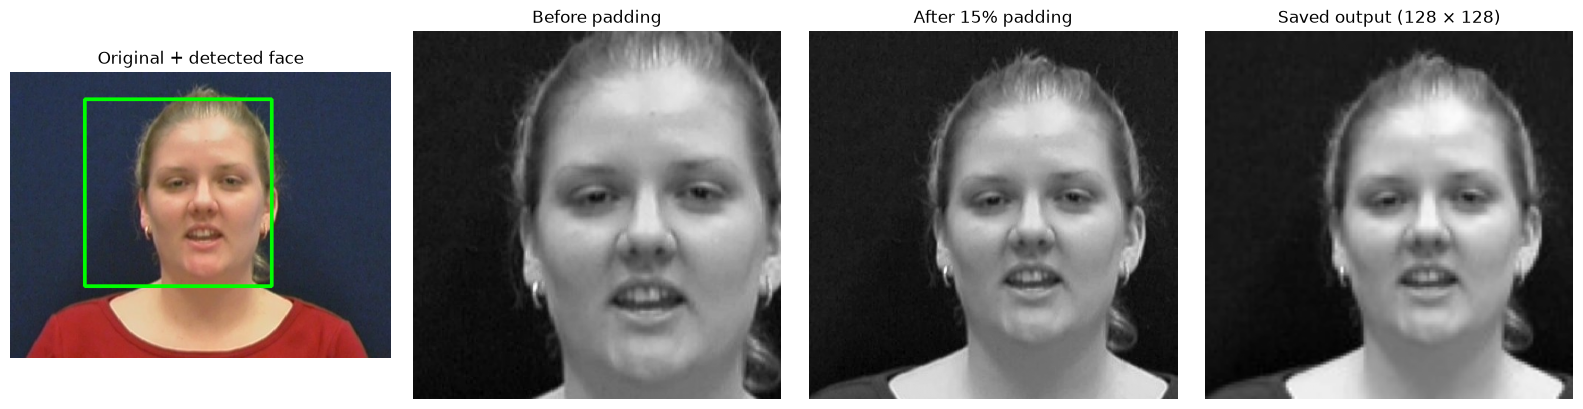

Detected box (x, y, width, height): (np.int32(100), np.int32(36), np.int32(251), np.int32(251))
Padding: horizontal=37px, vertical=37px
Final saved image shape: (128, 128)
Notebook reconstruction matches saved output: False


In [7]:
image = cv2.imread(str(original_path))
if image is None:
    raise FileNotFoundError(f'Could not read original image: {original_path}')

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
detection = detect_face(gray)
if detection is None:
    raise RuntimeError('The selected sample did not produce a face detection. Re-run the sample-selection cell.')

x, y, w, h = detection
image_height, image_width = gray.shape

# Crop exactly the detected bounding box (before padding).
before_padding = gray[y:y+h, x:x+w]

# Apply the same 15% padding and boundary handling as the project code.
pad_x = int(w * 0.15)
pad_y = int(h * 0.15)
x1 = max(0, x - pad_x)
y1 = max(0, y - pad_y)
x2 = min(image_width, x + w + pad_x)
y2 = min(image_height, y + h + pad_y)
after_padding = gray[y1:y2, x1:x2]

final_128 = cv2.resize(after_padding, (128, 128), interpolation=cv2.INTER_AREA)

# Load the actual saved result for a direct consistency check.
saved_result = cv2.imread(str(processed_path), cv2.IMREAD_GRAYSCALE)
if saved_result is None:
    raise FileNotFoundError(f'Could not read processed image: {processed_path}')

boxed = cv2.cvtColor(image.copy(), cv2.COLOR_BGR2RGB)
cv2.rectangle(boxed, (x, y), (x+w, y+h), (0, 255, 0), 3)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(boxed)
axes[0].set_title('Original + detected face')
axes[1].imshow(before_padding, cmap='gray')
axes[1].set_title('Before padding')
axes[2].imshow(after_padding, cmap='gray')
axes[2].set_title('After 15% padding')
axes[3].imshow(saved_result, cmap='gray')
axes[3].set_title('Saved output (128 × 128)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

print(f'Detected box (x, y, width, height): {detection}')
print(f'Padding: horizontal={pad_x}px, vertical={pad_y}px')
print('Final saved image shape:', saved_result.shape)
print('Notebook reconstruction matches saved output:', saved_result.shape == final_128.shape and (saved_result == final_128).all())


### Why do we add padding?

The detector returns a bounding box around the face. Adding 15% padding expands that region slightly, so the crop can retain some surrounding facial context instead of cutting tightly at the detected boundary. The padding is clipped at the image edges to avoid invalid coordinates.

### Why resize to 128 × 128?

All processed face images need a consistent spatial size before feature extraction. Resizing makes the input dimensions uniform across samples. The implementation uses OpenCV's `INTER_AREA` interpolation.


## 7. Examples of failed detections

The next cell displays a few original frames that the completed pipeline marked as `No face detected`. This helps explain the limitations of Haar Cascade, especially on challenging head poses. It only displays existing failed examples; it does not rerun the full pipeline.


Failed detections in report: 3611


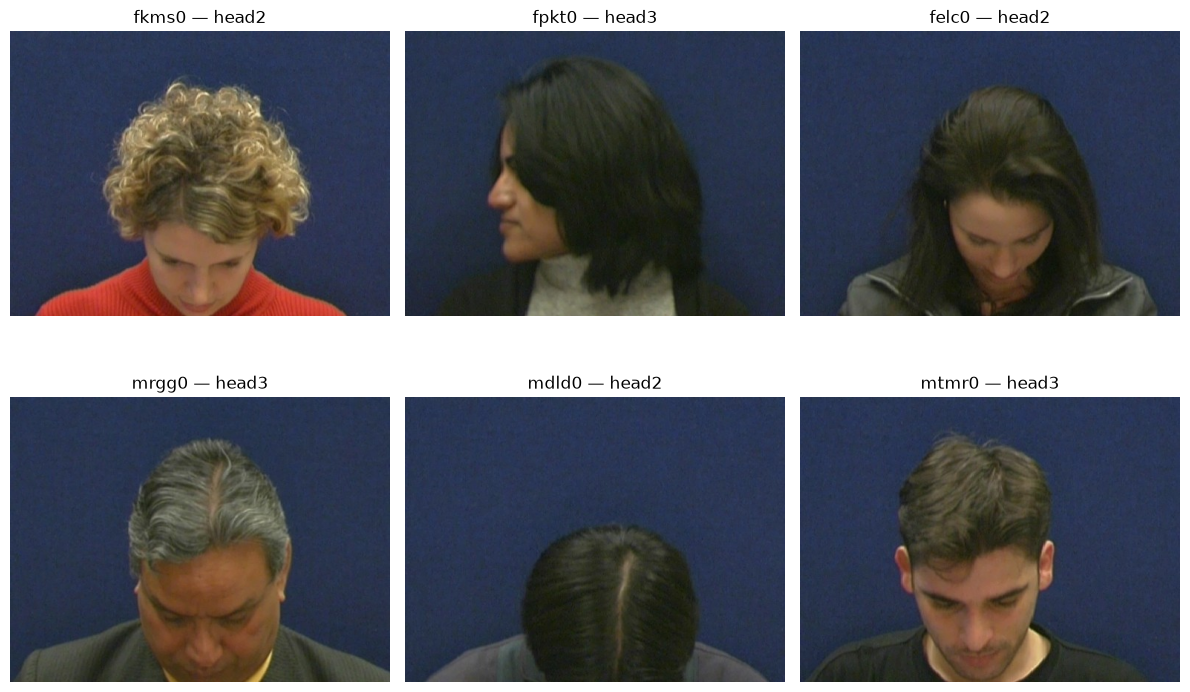

In [8]:
failed_rows = report[report['status'] == 'No face detected'].copy()
print('Failed detections in report:', len(failed_rows))
if failed_rows.empty:
    print('No failed detections with status exactly "No face detected".')
else:
    sample_failures = failed_rows.sample(min(6, len(failed_rows)), random_state=11)
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, (_, row) in zip(axes.flat, sample_failures.iterrows()):
        p = Path(row['original_file'])
        if not p.is_absolute(): p = PROJECT_ROOT / p
        frame = cv2.imread(str(p))
        if frame is not None:
            ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            ax.set_title(f"{row['speaker']} — {row['sequence']}")
        else:
            ax.set_title('Image could not be loaded')
        ax.axis('off')
    for ax in axes.flat[len(sample_failures):]: ax.axis('off')
    plt.tight_layout()
    plt.show()


## 8. Quantitative results

The following cells calculate the final counts directly from `face_preprocessing_report.csv` and visualize the success/failure distribution.


In [9]:
status_counts = report['status'].value_counts(dropna=False)
display(status_counts.rename_axis('Status').to_frame('Frames'))

total_frames = len(report)
successful_frames = int((report['status'] == 'Success').sum())
failed_frames = total_frames - successful_frames
success_rate = successful_frames / total_frames * 100 if total_frames else 0

print(f'Total frames: {total_frames:,}')
print(f'Successfully processed: {successful_frames:,}')
print(f'Failed: {failed_frames:,}')
print(f'Success rate: {success_rate:.2f}%')


,Frames
Status,
Success,99931
No face detected,3611


Total frames: 103,542
Successfully processed: 99,931
Failed: 3,611
Success rate: 96.51%


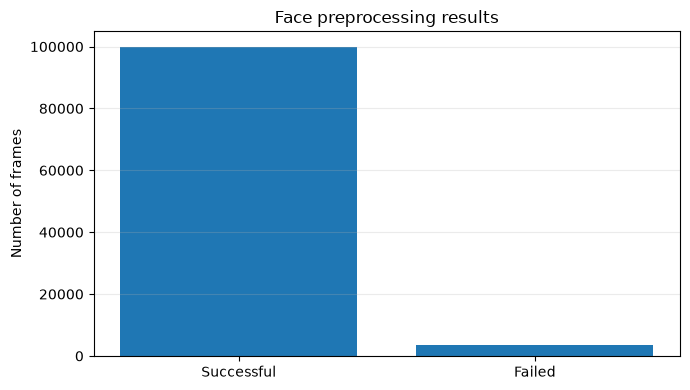

In [10]:
plt.figure(figsize=(7, 4))
plt.bar(['Successful', 'Failed'], [successful_frames, failed_frames])
plt.title('Face preprocessing results')
plt.ylabel('Number of frames')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## 9. Failure analysis by sequence

The completed report showed that the 3,611 failed detections were concentrated in the head-rotation sequences (`head`, `head2`, and `head3`). These sequences have no corresponding audio recordings in VidTIMIT, so they are not required for paired face–voice fusion. We still retain the report and the successfully processed head frames for analysis.


,Failed frames
sequence,
head2,1283
head3,1224
head,1104


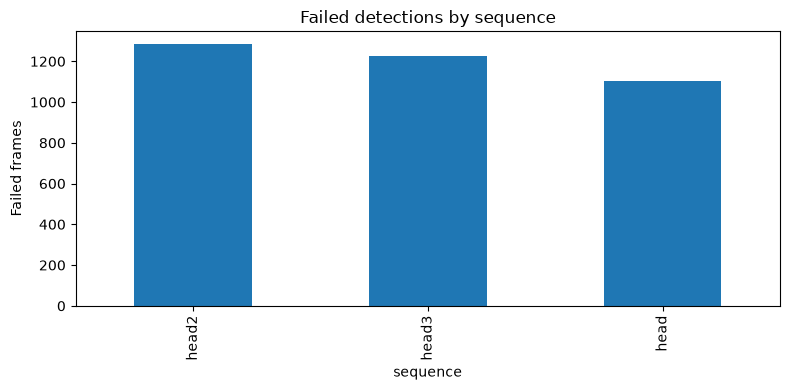

In [11]:
failure_by_sequence = (
    report[report['status'] != 'Success']
    .groupby('sequence', dropna=False)
    .size()
    .sort_values(ascending=False)
    .rename('Failed frames')
    .to_frame()
)
display(failure_by_sequence)
failure_by_sequence.plot(kind='bar', figsize=(8, 4), legend=False, title='Failed detections by sequence')
plt.ylabel('Failed frames')
plt.tight_layout()
plt.show()


## 10. Conclusion

- The pipeline processed **103,542** video frames from **43 speakers**.
- **99,931** frames were successfully processed.
- **3,611** frames were not successfully processed.
- The overall success rate was **96.51%**.
- The output face crops were converted to grayscale and resized to **128 × 128**.

The notebook demonstrates the actual pipeline decisions and their outputs using representative samples and the saved report. The main implementation remains in `src/preprocessing/face_preprocessing.py`.
